# Mini-Project 1: UBOS District Population Forecaster

**Scenario.** A district planning unit needs 5-year population forecasts (2025–2029) to plan primary-school classrooms.

**Data.** Population estimates in thousands for 2015–2024. All values are **illustrative** (synthetic). Kampala, Wakiso and Gulu come from the assignment brief. I made up **Mbarara** and **Arua** myself to show two other growth profiles: Mbarara grows steadily and slowly, and Arua has an uneven, step-like path, loosely inspired by refugee inflows into West Nile. Neither is real UBOS data.

All reusable logic is in [`src/population.py`](src/population.py). This notebook only runs that code and interprets the results.

In [1]:
import statistics

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.population import (
    CAGRForecaster,
    ClassroomPlanner,
    DistrictPopulation,
    FibonacciRatioForecaster,
    LinearTrendForecaster,
    ModelComparison,
    fibonacci_ratios,
)

SEED = 2026
rng = np.random.default_rng(SEED)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

## 1. The `DistrictPopulation` class

The class stores `years` and `populations` as NumPy arrays and validates them when it is created (equal lengths, no negative or non-finite values, years strictly increasing). It also implements `__repr__` and `__len__`.

In [2]:
YEARS = np.arange(2015, 2025)
raw = {
    "Kampala": [1200, 1250, 1300, 1350, 1420, 1500, 1580, 1650, 1720, 1800],
    "Wakiso":  [950, 1000, 1070, 1150, 1220, 1300, 1390, 1480, 1570, 1670],
    "Gulu":    [320, 330, 345, 360, 375, 390, 410, 430, 455, 480],
    # Added districts (illustrative, my own assumptions)
    "Mbarara": [470, 482, 495, 508, 520, 534, 548, 561, 575, 590],
    "Arua":    [780, 805, 835, 870, 880, 905, 935, 960, 990, 1020],
}
districts = [DistrictPopulation(name, YEARS, pops) for name, pops in raw.items()]
for d in districts:
    print(repr(d), "| len =", len(d))

DistrictPopulation(name='Kampala', years=2015-2024, n=10, last=1800k) | len = 10
DistrictPopulation(name='Wakiso', years=2015-2024, n=10, last=1670k) | len = 10
DistrictPopulation(name='Gulu', years=2015-2024, n=10, last=480k) | len = 10
DistrictPopulation(name='Mbarara', years=2015-2024, n=10, last=590k) | len = 10
DistrictPopulation(name='Arua', years=2015-2024, n=10, last=1020k) | len = 10


Validation in action: invalid input is rejected with a clear message.

In [3]:
for bad_years, bad_pops in [(YEARS, [100] * 9), (YEARS, [-1] + [100] * 9)]:
    try:
        DistrictPopulation("Bad", bad_years, bad_pops)
    except ValueError as err:
        print("Rejected:", err)

Rejected: years (10) and populations (9) differ in length
Rejected: populations cannot be negative


## 2. Descriptive statistics: `statistics` vs NumPy

In [4]:
rows = []
for d in districts:
    s = d.summary_statistics()
    n0 = d.numpy_statistics(ddof=0)
    n1 = d.numpy_statistics(ddof=1)
    rows.append({
        "district": d.name,
        "mean": s["mean"], "median": s["median"],
        "statistics.variance": s["variance"], "np.var (ddof=0)": n0["variance"], "np.var (ddof=1)": n1["variance"],
        "statistics.stdev": s["std"], "np.std (ddof=0)": n0["std"],
        "ratio var": s["variance"] / n0["variance"],
    })
stats_table = pd.DataFrame(rows).set_index("district")
stats_table

,mean,median,statistics.variance,np.var (ddof=0),np.var (ddof=1),statistics.stdev,np.std (ddof=0),ratio var
district,,,,,,,,
Kampala,"1,477.000","1,460.000","42,601.111","38,341.000","42,601.111",206.400,195.809,1.111
Wakiso,"1,280.000","1,260.000","60,066.667","54,060.000","60,066.667",245.085,232.508,1.111
Gulu,389.500,382.500,"2,885.833","2,597.250","2,885.833",53.720,50.963,1.111
Mbarara,528.300,527.000,"1,623.344","1,461.010","1,623.344",40.291,38.223,1.111
Arua,898.000,892.500,"6,251.111","5,626.000","6,251.111",79.064,75.007,1.111


**Why the two variances differ.** `statistics.variance` is the *sample* variance. It divides the sum of squared deviations by $n-1$. `np.var` defaults to the *population* variance, which divides by $n$. With $n = 10$ the ratio is always $10/9 \approx 1.111$, as the last column shows. The means and medians agree exactly.

**What `ddof` does.** `ddof` ("delta degrees of freedom") sets the divisor to $n - \text{ddof}$. With `ddof=1`, `np.var` gives exactly `statistics.variance`. That is Bessel's correction: the deviations are measured from the sample mean, which is itself fitted to the data, so one degree of freedom is used up and dividing by $n$ would underestimate the true variance. (`statistics.pvariance` is the equivalent of `ddof=0`.)

Note that for a *trending* series like these, the variance mostly measures how far the trend moved over ten years, not year-to-year volatility. This matters again in Section 6.

In [5]:
# Hand check for Gulu: sum of squared deviations / (n-1)
g = raw["Gulu"]
m = sum(g) / len(g)
ss = sum((x - m) ** 2 for x in g)
print(f"Gulu: mean={m}, SS={ss}, SS/(n-1)={ss / 9:.3f}, SS/n={ss / 10:.3f}")

Gulu: mean=389.5, SS=25972.5, SS/(n-1)=2885.833, SS/n=2597.250


## 3. Growth rates and CAGR

In [6]:
growth = pd.DataFrame({d.name: d.growth_rates() * 100 for d in districts}, index=YEARS[1:]).T
growth["CAGR %"] = [d.cagr() * 100 for d in districts]
growth = growth.sort_values("CAGR %", ascending=False)
growth.round(2)

,2016,2017,2018,2019,2020,2021,2022,2023,2024,CAGR %
Wakiso,5.260,7.000,7.480,6.090,6.560,6.920,6.470,6.080,6.370,6.470
Kampala,4.170,4.000,3.850,5.190,5.630,5.330,4.430,4.240,4.650,4.610
Gulu,3.120,4.550,4.350,4.170,4.000,5.130,4.880,5.810,5.490,4.610
Arua,3.210,3.730,4.190,1.150,2.840,3.310,2.670,3.120,3.030,3.030
Mbarara,2.550,2.700,2.630,2.360,2.690,2.620,2.370,2.500,2.610,2.560


In [7]:
fastest = growth["CAGR %"].idxmax()
print(f"Fastest relative growth: {fastest} at {growth.loc[fastest, 'CAGR %']:.2f}% per year")
# Hand check: Wakiso CAGR = (1670/950)^(1/9) - 1
print(f"Hand check Wakiso CAGR: {((1670 / 950) ** (1 / 9) - 1) * 100:.3f}%")

Fastest relative growth: Wakiso at 6.47% per year
Hand check Wakiso CAGR: 6.469%


## 4. Three forecasting models

All three models are subclasses of the abstract `Forecaster`, which defines `fit(years, values)`, `predict(horizon)` and `fitted_values()`. The base class also provides residual-bootstrap intervals, so every model gets them without duplicated code.

| Model | Rule |
|---|---|
| `LinearTrendForecaster` | least-squares line from `np.polyfit(years, values, 1)` |
| `CAGRForecaster` | $\hat y_{T+k} = y_T (1+g)^k$, with $g$ the training-period CAGR |
| `FibonacciRatioForecaster` | $\hat y_{T+k} = y_T \prod_{i=1}^{k} F_{i+1}/F_i$ (ratios 1, 2, 1.5, 1.67, 1.6, … → φ ≈ 1.618) |

In [8]:
print("Fibonacci ratios used for a 5-step forecast:", np.round(fibonacci_ratios(5), 3))
demo = LinearTrendForecaster()
print(demo, "->", demo.fit(YEARS, raw["Gulu"]), "| 2025-2027:", np.round(demo.predict(3), 1))

Fibonacci ratios used for a 5-step forecast: [1.    2.    1.5   1.667 1.6  ]
LinearTrendForecaster(fitted) -> LinearTrendForecaster(fitted) | 2025-2027: [486.3 503.9 521.5]


## 5. Validate before forecasting: train 2015–2021, test 2022–2024

In [9]:
def make_models():
    return [LinearTrendForecaster(), CAGRForecaster(), FibonacciRatioForecaster()]

comparisons, best_models = {}, {}
for d in districts:
    comp = ModelComparison(d, make_models(), last_train_year=2021)
    table = comp.run()
    comparisons[d.name] = comp
    best_models[d.name] = table.index[0]
    print(f"\n=== {d.name} (test 2022-2024) — best by RMSE: {table.index[0]}")
    display(table)


=== Kampala (test 2022-2024) — best by RMSE: Exponential (CAGR)


,MAE,RMSE,MAPE
Exponential (CAGR),9.619,10.385,0.551
Linear trend,37.619,38.975,2.165
Fibonacci ratio,"1,483.333","1,890.511",83.766



=== Wakiso (test 2022-2024) — best by RMSE: Exponential (CAGR)


,MAE,RMSE,MAPE
Exponential (CAGR),6.802,8.049,0.420
Linear trend,49.405,52.368,3.094
Fibonacci ratio,"1,266.667","1,604.390",77.617



=== Gulu (test 2022-2024) — best by RMSE: Exponential (CAGR)


,MAE,RMSE,MAPE
Exponential (CAGR),9.437,10.869,2.025
Linear trend,18.571,20.287,4.009
Fibonacci ratio,378.333,481.707,80.374



=== Mbarara (test 2022-2024) — best by RMSE: Exponential (CAGR)


,MAE,RMSE,MAPE
Exponential (CAGR),1.570,1.591,0.272
Linear trend,2.369,2.691,0.407
Fibonacci ratio,529.333,678.853,90.523



=== Arua (test 2022-2024) — best by RMSE: Exponential (CAGR)


,MAE,RMSE,MAPE
Exponential (CAGR),3.534,3.540,0.357
Linear trend,4.643,5.994,0.460
Fibonacci ratio,896.667,"1,149.094",88.831


In [10]:
summary = pd.DataFrame({
    name: comp.run().loc[best_models[name]] for name, comp in comparisons.items()
}).T
summary.insert(0, "selected model", pd.Series(best_models))
summary

,selected model,MAE,RMSE,MAPE
Kampala,Exponential (CAGR),9.619,10.385,0.551
Wakiso,Exponential (CAGR),6.802,8.049,0.420
Gulu,Exponential (CAGR),9.437,10.869,2.025
Mbarara,Exponential (CAGR),1.570,1.591,0.272
Arua,Exponential (CAGR),3.534,3.540,0.357


**Selection rule.** I choose the model with the lowest **RMSE** on the 2022–2024 hold-out. RMSE is in thousands of people, and because it squares errors it penalises large misses more heavily. A large miss is what causes a classroom shortage, so this is the error that matters most here. MAE and MAPE are reported as a cross-check. In every district all three metrics agree on the ranking.

## 6. Forecast 2025–2029 with the selected model and compare variances

The selected model is refitted on the full 2015–2024 series before forecasting. That uses all the data and is standard practice once the model *type* has been chosen.

In [11]:
MODEL_TYPES = {cls().name: cls for cls in (LinearTrendForecaster, CAGRForecaster, FibonacciRatioForecaster)}
HORIZON = 5
final = {}
var_rows = []
for d in districts:
    model = MODEL_TYPES[best_models[d.name]]().fit(d.years, d.populations)
    forecast = model.predict(HORIZON)
    lower, upper = model.bootstrap_interval(HORIZON, n_boot=1000, rng=rng)
    final[d.name] = {"model": model, "forecast": forecast, "lower": lower, "upper": upper}
    resid = d.populations - model.fitted_values()
    var_rows.append({
        "district": d.name,
        "var actual 2015-24": statistics.variance(d.populations.tolist()),
        "var forecast 2025-29": statistics.variance(forecast.tolist()),
        "var of residuals": statistics.variance(resid.tolist()),
        "forecast 2029": forecast[-1],
        "95% PI 2029": f"[{lower[-1]:,.0f}, {upper[-1]:,.0f}]",
    })
forecast_table = pd.DataFrame(
    {d: np.round(v["forecast"], 1) for d, v in final.items()}, index=final["Kampala"]["model"].forecast_years(HORIZON).astype(int)
).T
display(forecast_table)
pd.DataFrame(var_rows).set_index("district")

,2025,2026,2027,2028,2029
Kampala,"1,882.900","1,969.700","2,060.500","2,155.400","2,254.800"
Wakiso,"1,778.000","1,893.000","2,015.500","2,145.900","2,284.700"
Gulu,502.100,525.300,549.500,574.800,601.300
Mbarara,605.100,620.600,636.500,652.700,669.400
Arua,"1,050.900","1,082.700","1,115.400","1,149.200","1,183.900"


,var actual 2015-24,var forecast 2025-29,var of residuals,forecast 2029,95% PI 2029
district,,,,,
Kampala,"42,601.111","21,607.682",98.753,"2,254.763","[2,207, 2,297]"
Wakiso,"60,066.667","40,131.362",30.900,"2,284.671","[2,254, 2,311]"
Gulu,"2,885.833","1,536.546",13.819,601.270,"[586, 618]"
Mbarara,"1,623.344",647.066,0.234,669.446,"[668, 671]"
Arua,"6,251.111","2,767.086",30.418,"1,183.929","[1,165, 1,211]"


**What the variance difference tells us.** The forecast series has a much *smaller* variance than the actual series. That does **not** mean the future is more certain. There are two separate effects:

1. **Span.** The actual series covers 10 years of trend and the forecast covers 5. For a straight line the variance grows with the square of the span, so a 5-point line has roughly a quarter of the variance of a 10-point line with the same slope.
2. **No noise.** A forecast is a smooth curve with no year-to-year randomness. The "var of residuals" column shows the noise the model leaves unexplained in the actual data. None of that noise is in the point forecast.

If the slope stayed the same, the span effect alone would give a forecast/actual variance ratio of $(5^2-1)/(10^2-1) \approx 0.24$. The observed ratios are **0.40–0.67** (computed below). They are higher because the exponential model adds *more* people each year than the historical average. For example, Wakiso adds about 108k–139k a year in the forecast against an average of 80k in 2015–2024, and variance scales with the slope squared. The last column of the table below rescales the span-only figure by the squared change in slope, and that accounts for most of the gap. So the variance difference tells us how steep the extrapolated trend is (it is steeper than in the past), not how certain the forecast is.

Uncertainty should instead be shown as a prediction interval (the bootstrap columns and shaded bands below), which *widens* with the horizon.

In [12]:
var_df = pd.DataFrame(var_rows).set_index("district")
ratio = var_df["var forecast 2025-29"] / var_df["var actual 2015-24"]
slope_ratio = pd.Series({d: np.mean(np.diff(final[d]["forecast"])) / np.mean(np.diff(raw[d])) for d in raw})
pd.DataFrame({
    "variance ratio (forecast/actual)": ratio,
    "span-only expectation": 24 / 99,
    "(forecast slope / past slope)^2 x 24/99": slope_ratio**2 * 24 / 99,
}).round(3)

,variance ratio (forecast/actual),span-only expectation,(forecast slope / past slope)^2 x 24/99
Kampala,0.507,0.242,0.471
Wakiso,0.668,0.242,0.608
Gulu,0.532,0.242,0.471
Mbarara,0.399,0.242,0.353
Arua,0.443,0.242,0.377


## 7. Actual, fitted and forecast values (one figure, one panel per district)

In each panel:
- the black dots are the actual data;
- the dashed line is the selected model fitted on 2015–2021 together with its 2022–2024 test predictions (grey zone);
- the solid line is the 2025–2029 forecast from the model refitted on all data, with its 95% bootstrap band.

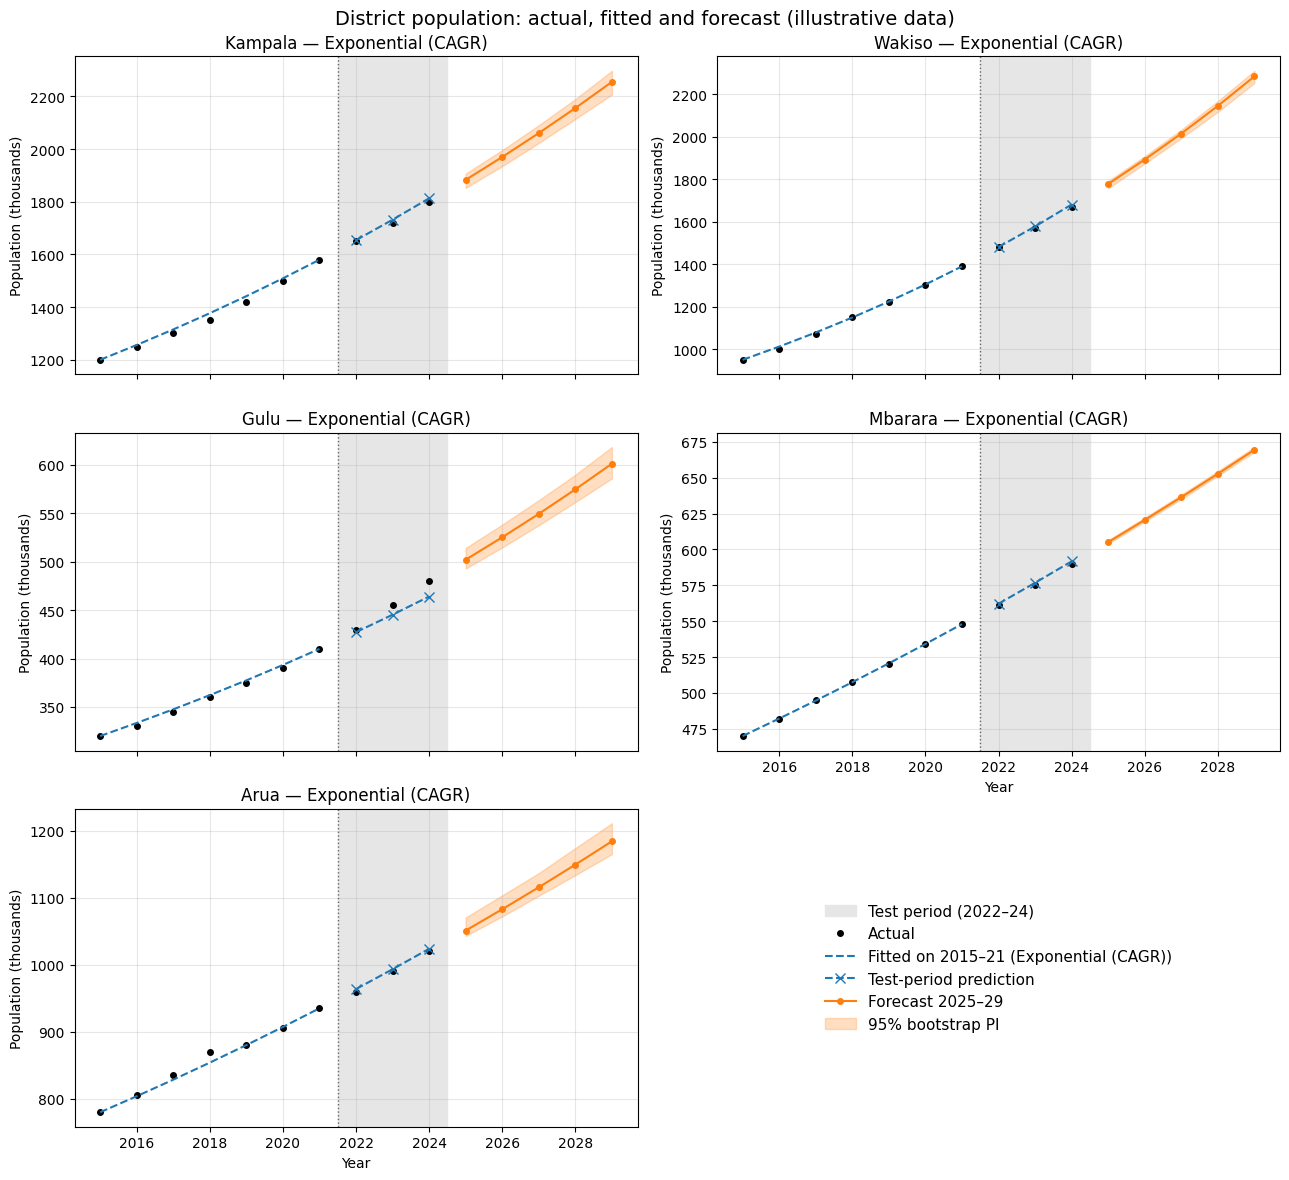

In [13]:
fig, axes = plt.subplots(3, 2, figsize=(13, 12), sharex=True)
axes = axes.ravel()
for ax, d in zip(axes, districts):
    comp = comparisons[d.name]
    name = best_models[d.name]
    train_model = next(m for m in comp.models if m.name == name)
    f = final[d.name]
    fyears = f["model"].forecast_years(HORIZON)
    ax.axvspan(2021.5, 2024.5, color="0.9", label="Test period (2022–24)")
    ax.axvline(2021.5, color="0.4", lw=1, ls=":")
    ax.plot(d.years, d.populations, "ko", ms=4, label="Actual")
    ax.plot(comp.train.years, train_model.fitted_values(), "C0--", label=f"Fitted on 2015–21 ({name})")
    ax.plot(comp.test.years, comp.predictions[name], "C0x--", ms=7, label="Test-period prediction")
    ax.plot(fyears, f["forecast"], "C1-o", ms=4, label="Forecast 2025–29")
    ax.fill_between(fyears, f["lower"], f["upper"], color="C1", alpha=0.25, label="95% bootstrap PI")
    ax.set_title(f"{d.name} — {name}")
    ax.set_ylabel("Population (thousands)")
    ax.grid(alpha=0.3)
for ax in axes[3:5]:
    ax.set_xlabel("Year")
    ax.xaxis.set_tick_params(labelbottom=True)
handles, labels = axes[0].get_legend_handles_labels()
axes[-1].axis("off")
axes[-1].legend(handles, labels, loc="center", fontsize=11, frameon=False)
fig.suptitle("District population: actual, fitted and forecast (illustrative data)", fontsize=14)
fig.tight_layout()
plt.show()

## 8. Planning output: additional classrooms needed by 2029

Assumptions from the brief: 18% of the population is of primary-school age and each classroom holds 53 pupils. "Additional" means the classrooms needed for the *growth* between 2024 and 2029, assuming the current stock already serves the 2024 population. That is optimistic for Uganda, where classrooms are already overcrowded, so these numbers are a floor. I round up because a fraction of a classroom still has to be built. The bootstrap interval gives a planning range.

In [14]:
planner = ClassroomPlanner(school_age_share=0.18, pupils_per_classroom=53)
plan_rows = []
for d in districts:
    f = final[d.name]
    now = d.populations[-1]
    plan_rows.append({
        "district": d.name,
        "pop 2024 (k)": now,
        "pop 2029 forecast (k)": f["forecast"][-1],
        "extra pupils": (f["forecast"][-1] - now) * 1000 * planner.school_age_share,
        "additional classrooms": planner.additional_classrooms(now, f["forecast"][-1]),
        "range (95% PI)": f"{planner.additional_classrooms(now, f['lower'][-1])}–{planner.additional_classrooms(now, f['upper'][-1])}",
    })
plan = pd.DataFrame(plan_rows).set_index("district")
display(plan.style.format({"pop 2024 (k)": "{:,.0f}", "pop 2029 forecast (k)": "{:,.1f}", "extra pupils": "{:,.0f}"}))
print("Total additional classrooms across the five districts:", plan["additional classrooms"].sum())

,pop 2024 (k),pop 2029 forecast (k),extra pupils,additional classrooms,range (95% PI)
district,,,,,
Kampala,"1,800","2,254.8","81,857",1545,1382–1688
Wakiso,"1,670","2,284.7","110,641",2088,1983–2177
Gulu,480,601.3,"21,829",412,361–471
Mbarara,590,669.4,"14,300",270,265–277
Arua,"1,020","1,183.9","29,507",557,493–649


Total additional classrooms across the five districts: 4872


In [15]:
# Hand check for Gulu with the numbers above
g29 = final["Gulu"]["forecast"][-1]
print(f"Gulu: ({g29:.1f} - 480) * 1000 * 0.18 / 53 = {(g29 - 480) * 1000 * 0.18 / 53:.2f} -> round up")

Gulu: (601.3 - 480) * 1000 * 0.18 / 53 = 411.86 -> round up


## Extension A: 95% bootstrap prediction intervals

The intervals above come from `Forecaster.bootstrap_interval` with **1,000 resamples** of the centred in-sample residuals (seeded generator). Each resample (i) adds resampled residuals to the fitted values, (ii) refits the model, so the uncertainty in the slope or growth rate is captured, and (iii) adds one resampled residual to each forecast step for observation noise. The bands are narrow because the illustrative series are very smooth (residual SD is only a few thousand people). Real census-based estimates would give much wider bands.

## Extension B: Critical assessment of the Fibonacci-ratio model

In [16]:
print("Fibonacci-ratio test-period MAPE by district:")
for name, comp in comparisons.items():
    print(f"  {name:8s} {comp.run().loc['Fibonacci ratio', 'MAPE']:7.1f}%")
print("\nImplied annual growth of each forecast step:", np.round((fibonacci_ratios(6) - 1) * 100, 1), "%")
print("Observed CAGRs:", {d.name: round(d.cagr() * 100, 2) for d in districts}, "%")

Fibonacci-ratio test-period MAPE by district:
  Kampala     83.8%
  Wakiso      77.6%
  Gulu        80.4%
  Mbarara     90.5%
  Arua        88.8%

Implied annual growth of each forecast step: [  0.  100.   50.   66.7  60.   62.5] %
Observed CAGRs: {'Kampala': 4.61, 'Wakiso': 6.47, 'Gulu': 4.61, 'Mbarara': 2.56, 'Arua': 3.03} %


The Fibonacci-ratio model assumes the population grows by $F_{k+1}/F_k - 1$ each year: 0%, then 100%, 50%, 67%, 60%, and then about **61.8% per year** for ever. It has no parameters estimated from the data, so it cannot adapt to a district growing at 2% or at 6%. Its only link to the data is the last observed value.

It would be defensible only if (a) each year's population were the sum of the previous two years' populations, as in Fibonacci's rabbit model with no deaths and a fixed two-period maturation lag, and (b) growth were unconstrained by land, food or mortality. Neither holds for human populations. Uganda's population grows at roughly 3% a year, which is a ratio of 1.03, not 1.618. Even the first step (ratio 1, zero growth) is wrong for every district.

If any version is defensible, it is a heavily *damped* one, for example $\hat y_{T+k}=y_T\,(1+\lambda(\varphi-1))^k$ with λ fitted to the data. At that point the "Fibonacci" part does nothing and it is just the CAGR model under another name. **Conclusion:** the model should be dropped. The hold-out test above, where it has the worst error by an order of magnitude, is exactly the kind of check that would have caught this in the previous cohort's assignment.

## Findings & Limitations

**Findings.** The exponential (CAGR) model won the 2022–2024 hold-out in all five districts, with test MAPE between 0.3% and 2.0%. The linear trend came second each time, and the gap was widest in Wakiso (3.1% against 0.4%). That pattern is what you see when growth *compounds*: the number of people added each year keeps rising. Wakiso is both the fastest-growing district (CAGR 6.5%) and the one adding the most people (about 615k by 2029). It therefore needs the most new classrooms, about 2,090 of the roughly 4,870 total, more than Kampala even though Kampala is larger today. Gulu is a warning sign: its annual growth rose from about 3% to 5.5%, and the CAGR model *under-predicted* all three test years. Any constant-rate model will understate needs in a district whose growth is accelerating, so Gulu's ~412 classrooms should be treated as a lower bound.

**Limitations.** The data are illustrative and almost noise-free. The bootstrap intervals (for example ±45k for Kampala in 2029) therefore reflect only in-sample residual noise. They ignore structural shocks such as refugee inflows, census revisions or district boundary changes, which dominate real forecasting error in Uganda. Model selection rests on just three test points per district. The 18% school-age share and 53 pupils per classroom are held fixed, although Uganda's age structure is slowly shifting. The classroom figures also assume today's stock already meets demand, so the existing backlog is ignored and the numbers are a minimum. Finally, the CAGR model uses only the first and last training points. A log-linear regression would use every year and be less sensitive to an unusual endpoint.